# Laboratorio práctico de Machine Learning con datos reales
## Clasificación de variedades de frijol seco — CRISP-DM + TDSP + Scrum ML

**Universidad Autónoma de Occidente (UAO)** · Gestión de Proyectos de IA
**Dataset:** [Dry Bean Dataset — UCI ML Repository (id 602)](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset)

| Metodología | Cómo se refleja en este notebook |
|---|---|
| **CRISP-DM** | Cada sección está etiquetada con su fase (1 Negocio → 6 Despliegue). |
| **TDSP** | Rutas relativas a la estructura del repo (`data/`, `outputs/`, `src/`), semilla fija, artefactos versionados. |
| **Scrum ML** | Cada bloque indica la historia del backlog (PB-xx) y el sprint al que pertenece. Ver `docs/scrum/`. |

## CRISP-DM · Fase 1 — Comprensión del negocio

**Problema:** una empresa agrícola clasifica parte de sus granos de frijol de forma manual, lo que es lento e inconsistente.

**Objetivo de negocio:** automatizar la clasificación de la variedad del grano para mejorar el control de calidad.

**Objetivo de minería de datos:** construir un clasificador multiclase que prediga `Class` (7 variedades) a partir de 16 características geométricas extraídas de imágenes.

**Criterio de éxito:** priorizar **F1 macro** (todas las variedades pesan igual), revisar errores por clase y, si dos modelos rinden parecido, preferir el más simple.

## Paso 1 · Archivo de trabajo y entorno *(Sprint 1)*

Este es `notebooks/01_laboratorio_drybean.ipynb`. La versión en script está en `src/laboratorio_drybean.py`.
Se fija el directorio de trabajo en la raíz del repositorio para que las rutas TDSP (`outputs/models/...`) funcionen igual en notebook y en script.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
for folder in ["data/raw", "data/processed", "outputs/models", "outputs/reports/figures"]:
    Path(folder).mkdir(parents=True, exist_ok=True)
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: C:\Users\LENOVO\OneDrive\Escritorio\UNIVERSIDAD\Octavo semestre\Gestion de proyectos en IA y CD\gestion-ia-laboratorio


## Paso 2 · Importar librerías

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

import joblib

%matplotlib inline
pd.set_option("display.width", 140)
RANDOM_STATE = 42

## CRISP-DM · Fase 2 — Comprensión de los datos

### Paso 3 · Cargar el dataset real desde UCI *(PB-01 · Sprint 1)*

Se descarga desde la fuente oficial. Si no hay internet, se usa la copia local versionada en `data/raw/` (decisión TDSP de reproducibilidad).

In [3]:
try:
    dry_bean = fetch_ucirepo(id=602)
    X = dry_bean.data.features
    y = dry_bean.data.targets
    df = pd.concat([X, y], axis=1)
    fuente = "UCI ML Repository (id=602)"
except Exception as exc:
    print("Sin acceso a UCI, se usa copia local:", exc)
    df = pd.read_excel("data/raw/Dry_Bean_Dataset.xlsx")
    # el .xlsx trae dos nombres con errata respecto a UCI
    df = df.rename(columns={"AspectRation": "AspectRatio", "roundness": "Roundness"})
    fuente = "data/raw/Dry_Bean_Dataset.xlsx"

df.to_csv("data/raw/dry_bean_raw.csv", index=False)
print("Fuente:", fuente)
df.head()

Fuente: UCI ML Repository (id=602)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


**Actividad del estudiante — respuestas**

1. **¿Cuántas columnas tiene el dataset?** 17: 16 variables predictoras (geométricas) + 1 variable objetivo.
2. **¿Cuál es la variable objetivo?** `Class`, la variedad del frijol (BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA).
3. **¿Clasificación o regresión?** Clasificación **multiclase** (7 clases): la salida es una categoría, no un valor continuo.

### Paso 4 · Comprensión de datos según CRISP-DM

In [4]:
print(df.shape)
df.info()

(13611, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtype

In [5]:
df.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985
AspectRatio,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


In [6]:
no_numericas = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
print("Columnas no numéricas:", no_numericas)

# Posibles valores extremos: regla IQR por variable
q1, q3 = df.drop(columns="Class").quantile(0.25), df.drop(columns="Class").quantile(0.75)
iqr = q3 - q1
num = df.drop(columns="Class")
outliers = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
outliers.head(8)

Columnas no numéricas: ['Class']


Eccentricity       843
Solidity           778
ShapeFactor4       767
MinorAxisLength    569
Area               551
ConvexArea         550
ShapeFactor1       533
EquivDiameter      526
dtype: int64

**Interpretación**

- **Registros:** 13.611 · **Variables:** 16 predictoras + `Class`.
- **Tipos:** 14 variables `float64` y 2 `int64` (`Area`, `ConvexArea`); la única columna no numérica es `Class`.
- **Escalas muy distintas:** `Area` está en decenas de miles de píxeles, mientras `ShapeFactor1` es del orden de 0.006 → justifica `StandardScaler` para modelos lineales.
- **Valores extremos:** hay muchos valores fuera del rango IQR, pero no son errores de medición sino rasgos de una variedad: de los 551 extremos en `Area`, **522 son BOMBAY** (todos los granos de esa variedad, la más grande); de los 843 en `Eccentricity`, **828 son SEKER** (la más redonda). Por eso **no se eliminan**: son justamente la información que separa las clases.

### Paso 5 · Revisar valores nulos y duplicados *(PB-02 · Sprint 1)*

In [7]:
missing_values = df.isna().sum()
duplicated_rows = df.duplicated().sum()

print(missing_values)
print("Filas duplicadas:", duplicated_rows)

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
Roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64
Filas duplicadas: 68


**Decisión técnica:** no hay valores nulos, pero sí **68 filas duplicadas** exactas. Se eliminan para que el modelo no vea observaciones repetidas (y para evitar que una misma fila quede a la vez en train y en test, lo que inflaría las métricas).

In [8]:
df = df.drop_duplicates().reset_index(drop=True)
df.to_csv("data/processed/dry_bean_clean.csv", index=False)
print("Shape tras eliminar duplicados:", df.shape)

Shape tras eliminar duplicados: (13543, 17)


### Paso 6 · Analizar la variable objetivo

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Class
DERMASON    26.2 %
SIRA        19.5 %
SEKER       15.0 %
HOROZ       13.7 %
CALI        12.0 %
BARBUNYA     9.8 %
BOMBAY       3.9 %
Name: count, dtype: object


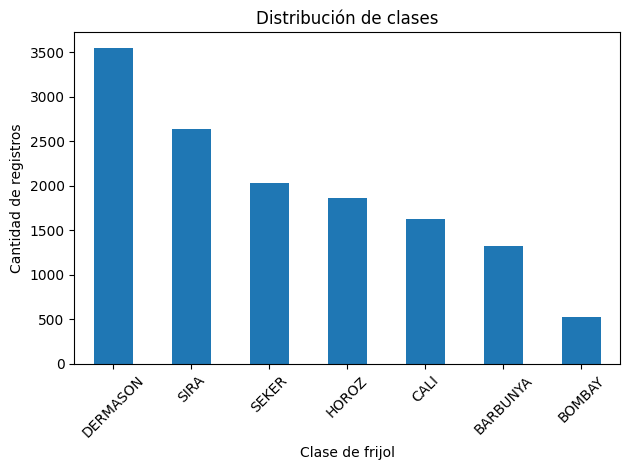

In [9]:
class_counts = df["Class"].value_counts()
print(class_counts)
print((class_counts / class_counts.sum() * 100).round(1).astype(str) + " %")

class_counts.plot(kind="bar")
plt.title("Distribución de clases")
plt.xlabel("Clase de frijol")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/reports/figures/distribucion_clases.png", dpi=120)
plt.show()

**¿Las clases están balanceadas?** No. DERMASON tiene 3.546 registros (≈26 %) y BOMBAY solo 522 (≈4 %): una relación cercana a **7:1**.

**Efecto en el entrenamiento:** un modelo tiende a favorecer las clases mayoritarias porque reducir su error baja más la pérdida global; el *accuracy* puede verse alto aunque una clase minoritaria se clasifique mal. Mitigaciones usadas en este laboratorio: `stratify=y` en la partición, `class_weight="balanced"` en Random Forest y **F1 macro** como métrica principal.

## CRISP-DM · Fase 3 — Preparación de los datos

### Paso 7 · Separar variables predictoras y objetivo

In [10]:
X = df.drop(columns="Class")
y = df["Class"]
X.shape, y.shape

((13543, 16), (13543,))

### Paso 8 · Separar entrenamiento y prueba

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({"train %": y_train.value_counts(normalize=True).round(3),
              "test %": y_test.value_counts(normalize=True).round(3)})

Train: (10834, 16) | Test: (2709, 16)


,train %,test %
Class,,
DERMASON,0.262,0.262
SIRA,0.195,0.195
SEKER,0.150,0.150
HOROZ,0.137,0.137
CALI,0.120,0.120
BARBUNYA,0.098,0.098
BOMBAY,0.039,0.038


**Conexión con TDSP:** `random_state=42` queda documentado aquí, en `src/config.py` y en `docs/reporte_final.md`, de modo que otro equipo obtiene exactamente la misma partición. La tabla confirma que `stratify=y` conserva las proporciones de clase en ambos subconjuntos.

**Pipeline de preprocesamiento:** el escalado se hace **dentro** de un `Pipeline` (paso 9), así `StandardScaler` se ajusta solo con datos de entrenamiento y no hay fuga de información hacia el test.

## CRISP-DM · Fase 4 — Modelado *(Sprint 2)*

### Paso 9 · Modelo baseline con regresión logística *(PB-03)*

In [12]:
baseline_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

baseline_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


**¿Por qué baseline?** Es un modelo sencillo, rápido e interpretable que fija el piso de desempeño. Un modelo más complejo solo se justifica si lo supera de forma clara.

## CRISP-DM · Fase 5 — Evaluación

### Paso 10 · Evaluar el modelo baseline

In [13]:
y_pred_baseline = baseline_model.predict(X_test)

accuracy_baseline = accuracy_score(y_test, y_pred_baseline)
f1_baseline = f1_score(y_test, y_pred_baseline, average="macro")

print("Accuracy baseline:", round(accuracy_baseline, 4))
print("F1 macro baseline:", round(f1_baseline, 4))
print(classification_report(y_test, y_pred_baseline, digits=4))

Accuracy baseline: 0.9195
F1 macro baseline: 0.9306
              precision    recall  f1-score   support

    BARBUNYA     0.9255    0.8906    0.9077       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9110    0.9417    0.9261       326
    DERMASON     0.9265    0.9069    0.9166       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9319    0.9433    0.9376       406
        SIRA     0.8585    0.8861    0.8721       527

    accuracy                         0.9195      2709
   macro avg     0.9311    0.9303    0.9306      2709
weighted avg     0.9201    0.9195    0.9197      2709



**¿Por qué F1 macro puede ser más informativo que accuracy?** El *accuracy* cuenta aciertos globales, así que lo dominan las clases grandes (DERMASON, SIRA). El **F1 macro** calcula el F1 de cada clase (equilibrio entre precisión y recall) y los promedia **con el mismo peso**, de modo que un mal desempeño en BOMBAY o BARBUNYA sí baja la métrica. Para control de calidad interesa clasificar bien **todas** las variedades, no solo las abundantes.

### Paso 11 · Modelo mejorado con Random Forest *(PB-04)*

In [14]:
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


**Nota técnica:** Random Forest no requiere escalamiento porque los árboles dividen por umbrales sobre cada variable; la escala no cambia el orden de los valores.

### Paso 12 · Evaluar Random Forest

In [15]:
y_pred_forest = forest_model.predict(X_test)

accuracy_forest = accuracy_score(y_test, y_pred_forest)
f1_forest = f1_score(y_test, y_pred_forest, average="macro")

print("Accuracy Random Forest:", round(accuracy_forest, 4))
print("F1 macro Random Forest:", round(f1_forest, 4))
print(classification_report(y_test, y_pred_forest, digits=4))

Accuracy Random Forest: 0.9192
F1 macro Random Forest: 0.9303
              precision    recall  f1-score   support

    BARBUNYA     0.9216    0.8868    0.9038       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9187    0.9356    0.9271       326
    DERMASON     0.9085    0.9238    0.9161       709
       HOROZ     0.9617    0.9462    0.9539       372
       SEKER     0.9462    0.9532    0.9497       406
        SIRA     0.8659    0.8577    0.8618       527

    accuracy                         0.9192      2709
   macro avg     0.9318    0.9290    0.9303      2709
weighted avg     0.9192    0.9192    0.9191      2709



### Paso 13 · Comparar modelos *(PB-05)*

In [16]:
results = pd.DataFrame({
    "modelo": ["Logistic Regression", "Random Forest"],
    "accuracy": [accuracy_baseline, accuracy_forest],
    "f1_macro": [f1_baseline, f1_forest]
})
results.to_csv("outputs/reports/comparacion_modelos.csv", index=False)
results.round(4)

,modelo,accuracy,f1_macro
0,Logistic Regression,0.9195,0.9306
1,Random Forest,0.9192,0.9303


In [17]:
# Comparación por clase (F1)
f1_por_clase = pd.DataFrame({
    "LogReg": f1_score(y_test, y_pred_baseline, average=None, labels=sorted(y.unique())),
    "RandomForest": f1_score(y_test, y_pred_forest, average=None, labels=sorted(y.unique())),
}, index=sorted(y.unique())).round(4)
f1_por_clase["diferencia"] = (f1_por_clase["RandomForest"] - f1_por_clase["LogReg"]).round(4)
f1_por_clase

,LogReg,RandomForest,diferencia
BARBUNYA,0.9077,0.9038,-0.0039
BOMBAY,1.0000,1.0000,0.0000
CALI,0.9261,0.9271,0.0010
DERMASON,0.9166,0.9161,-0.0005
HOROZ,0.9538,0.9539,0.0001
SEKER,0.9376,0.9497,0.0121
SIRA,0.8721,0.8618,-0.0103


**Decisión CRISP-DM**

- En el test, LR obtiene **accuracy 0,9195** y RF **0,9192**; el F1 macro es **0,9306 (LR)** vs **0,9303 (RF)**: una diferencia observada de 0,0003. No se hizo una prueba de significancia o equivalencia; una diferencia en F1 macro no se traduce directamente a un número de granos.
- Por clase, RF mejora ligeramente SEKER y CALI, y LR es algo mejor en SIRA. Ninguno domina.
- La validación cruzada (extensión A, más abajo) da LR 0,936 ± 0,007 vs RF 0,935 ± 0,004. Usa todo el dataset limpio, incluidas las filas del test, por lo que no constituye evidencia independiente de ese test ni demuestra equivalencia estadística. En futuros ajustes se debe usar CV sobre train y reservar una evaluación final independiente.

**Conclusión:** Random Forest **no supera de forma clara al baseline**. Aplicando el criterio del laboratorio (*preferir el modelo más simple si el desempeño es muy parecido*), la **regresión logística es la candidata recomendada para producción**: más liviana (≈3 KB vs ≈4,5 MB), más rápida e interpretable. Se guardan **ambos** modelos; el Random Forest se conserva como artefacto del laboratorio (pasos 16–18) y por su utilidad para explicar la importancia de variables.

### Paso 14 · Matriz de confusión

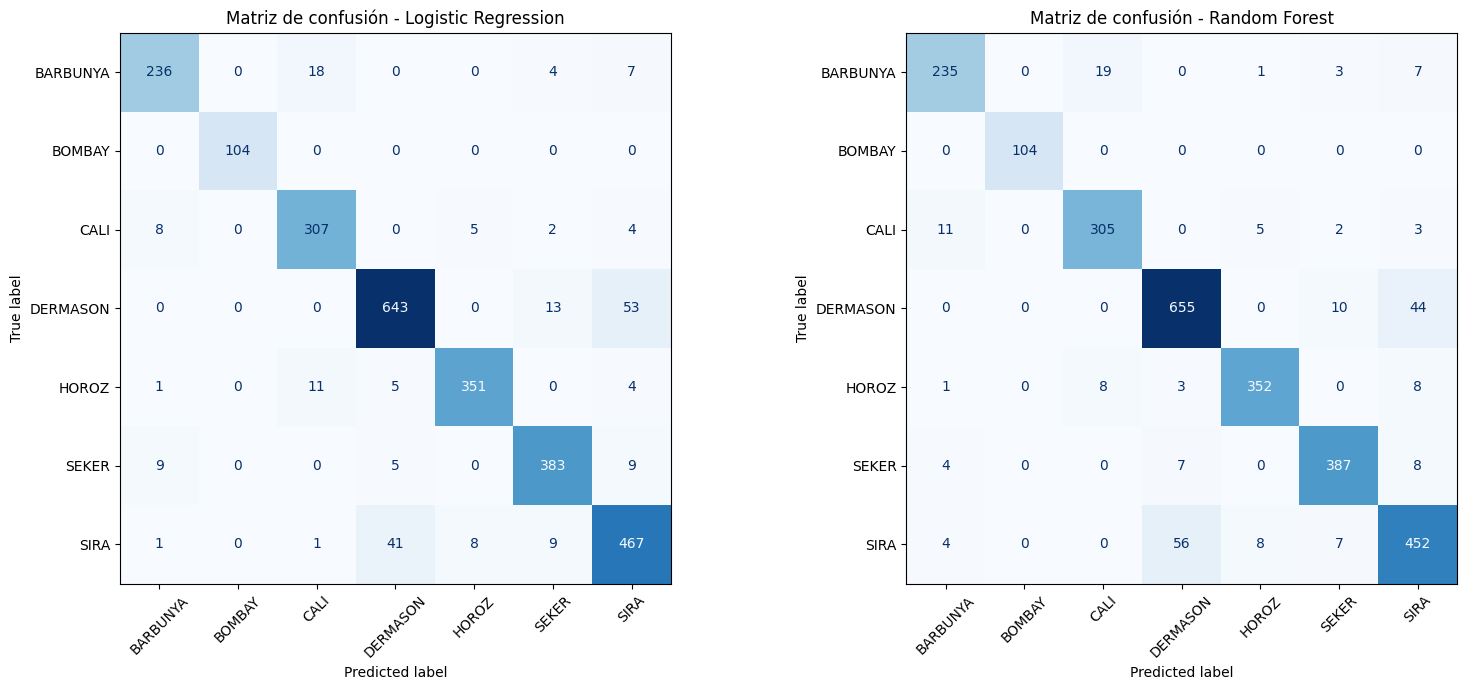

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, pred, name in [(axes[0], y_pred_baseline, "Logistic Regression"),
                       (axes[1], y_pred_forest, "Random Forest")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45, ax=ax,
                                            cmap="Blues", colorbar=False)
    ax.set_title(f"Matriz de confusión - {name}")
plt.tight_layout()
plt.savefig("outputs/reports/figures/matrices_confusion.png", dpi=120)
plt.show()

In [19]:
errores = pd.DataFrame({"real": y_test.values, "predicho": y_pred_forest})
errores = errores[errores.real != errores.predicho]
print("Errores totales RF:", len(errores))
errores.value_counts().rename("errores").reset_index().head(6)

Errores totales RF: 219


,real,predicho,errores
0,SIRA,DERMASON,56
1,DERMASON,SIRA,44
2,BARBUNYA,CALI,19
3,CALI,BARBUNYA,11
4,DERMASON,SEKER,10
5,HOROZ,CALI,8


In [20]:
# ¿Por qué se confunden? Comparación de medias por clase en variables de tamaño y forma
df.groupby("Class")[["Area", "Perimeter", "MajorAxisLength", "Compactness", "Roundness", "ShapeFactor1"]].mean().round(4)

,Area,Perimeter,MajorAxisLength,Compactness,Roundness,ShapeFactor1
Class,,,,,,
BARBUNYA,69804.1331,1046.1058,370.0443,0.8050,0.8002,0.0054
BOMBAY,173485.0594,1585.6191,593.1521,0.7926,0.8644,0.0034
CALI,75538.2110,1057.6343,409.4995,0.7567,0.8459,0.0055
DERMASON,32118.7109,665.2095,246.5573,0.8191,0.9081,0.0078
HOROZ,53671.7328,920.1086,372.6939,0.7008,0.7944,0.0070
SEKER,39881.3000,727.6724,251.2920,0.8968,0.9445,0.0063
SIRA,44729.1286,796.4187,299.3803,0.7973,0.8847,0.0067


**¿Qué clases se confunden más?**

1. **SIRA ↔ DERMASON** (≈100 errores entre ambos sentidos, casi la mitad de todos los errores). Son dos variedades **pequeñas y de forma muy parecida**: compactness ≈0,80–0,82, roundness similar y áreas solapadas (≈32.000 vs ≈44.700 px con distribuciones que se cruzan). Los granos grandes de DERMASON y los pequeños de SIRA son prácticamente indistinguibles con solo geometría 2D.
2. **BARBUNYA ↔ CALI** (≈28 errores). Ambas son **grandes** (área ≈70.000–75.000 px) y con perímetros casi iguales; se diferencian sobre todo por el color/patrón de la cáscara (BARBUNYA es moteada), información que **no** está en las variables geométricas.
3. **DERMASON → SEKER**: SEKER es la más redonda (compactness ≈0,90), pero los DERMASON más redondos caen en su región.
4. **BOMBAY** se clasifica perfecto (F1 = 1,0): su tamaño (≈173.000 px, más del doble que cualquier otra) la separa trivialmente.

### Paso 15 · Importancia de variables

In [21]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)
feature_importance.to_csv("outputs/reports/importancia_variables.csv", index=False)
print(feature_importance.head(10))

            feature  importance
1         Perimeter    0.110626
12     ShapeFactor1    0.103799
11      Compactness    0.100588
14     ShapeFactor3    0.096586
3   MinorAxisLength    0.082270
7     EquivDiameter    0.065426
5      Eccentricity    0.063598
10        Roundness    0.060568
6        ConvexArea    0.058507
0              Area    0.058484


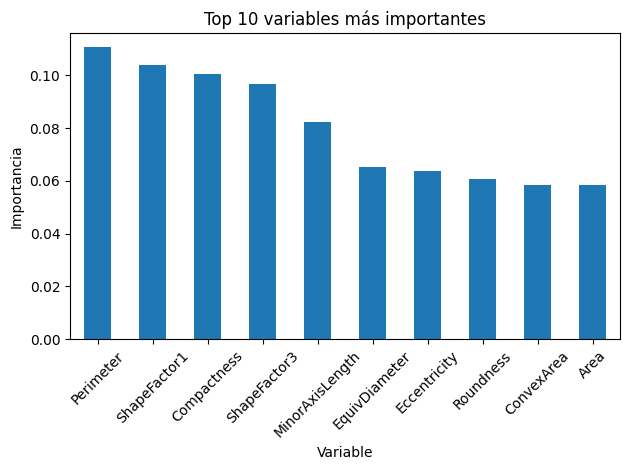

In [22]:
feature_importance.head(10).plot(
    x="feature",
    y="importance",
    kind="bar",
    legend=False
)
plt.title("Top 10 variables más importantes")
plt.xlabel("Variable")
plt.ylabel("Importancia")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/reports/figures/importancia_variables.png", dpi=120)
plt.show()

**Lectura:** las variables más útiles combinan **tamaño** (`Perimeter`, `MinorAxisLength`) y **forma** (`ShapeFactor1`, `Compactness`, `ShapeFactor3`). La importancia está muy repartida porque muchas variables son redundantes entre sí (por ejemplo `Area`, `ConvexArea` y `EquivDiameter` miden casi lo mismo), y el bosque reparte el mérito entre ellas.

**Ojo:** la importancia explica qué variables usó el modelo para separar clases; **no** prueba causalidad.

## CRISP-DM · Fase 6 — Despliegue *(Sprint 3)*

### Paso 16 · Guardar el modelo entrenado *(PB-07)*

In [23]:
joblib.dump(forest_model, "outputs/models/random_forest_drybean.joblib", compress=3)
joblib.dump(baseline_model, "outputs/models/logistic_regression_drybean.joblib")
for p in Path("outputs/models").glob("*.joblib"):
    print(f"{p.name}: {p.stat().st_size / 1024:.1f} KB")

logistic_regression_drybean.joblib: 3.3 KB
random_forest_drybean.joblib: 7056.2 KB


**Conexión con TDSP:** el modelo queda versionado junto al código que lo produjo; cualquiera puede cargarlo sin reentrenar. Se usa `compress=3` para que el Random Forest (≈4,5 MB) quepa cómodamente en GitHub.

### Paso 17 · Cargar el modelo y probar una predicción

In [24]:
loaded_model = joblib.load("outputs/models/random_forest_drybean.joblib")

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)

print("Predicción:", prediction[0])
print("Valor real:", y_test.iloc[0])

Predicción: SEKER
Valor real: SEKER


### Paso 18 · Mini despliegue local con función reutilizable

In [25]:
def predict_bean_class(model, input_data):
    prediction = model.predict(input_data)
    return prediction[0]

example_prediction = predict_bean_class(loaded_model, sample)
print(example_prediction)

# Verificación: el modelo cargado reproduce exactamente las predicciones originales
assert (loaded_model.predict(X_test) == y_pred_forest).all()
print("Modelo cargado = modelo entrenado ✔")

SEKER
Modelo cargado = modelo entrenado ✔


La misma función está empaquetada en `src/predict.py` y se puede usar desde consola:

```bash
python -m src.predict --input data/processed/dry_bean_clean.csv --n 5
```

## Extensiones opcionales

### Opción A · Validación cruzada
Una sola partición train/test puede ser afortunada. Con 5 folds estratificados se mide la **estabilidad**.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in [("Logistic Regression", baseline_model), ("Random Forest", forest_model)]:
    scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_rows.append({"modelo": name, "f1_macro_media": scores.mean(), "f1_macro_std": scores.std(),
                    "folds": np.round(scores, 4).tolist()})
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv("outputs/reports/validacion_cruzada.csv", index=False)
cv_results.round(4)

,modelo,f1_macro_media,f1_macro_std,folds
0,Logistic Regression,0.9359,0.0071,"[0.9273, 0.9414, 0.9398, 0.9436, 0.9272]"
1,Random Forest,0.9347,0.0043,"[0.9277, 0.9398, 0.9361, 0.9378, 0.9322]"


Ambos modelos son estables (desviación < 0,01) y prácticamente iguales; la regresión logística queda incluso ligeramente arriba, lo que refuerza la decisión de preferir el modelo simple.

### Opción B · Búsqueda de hiperparámetros (GridSearchCV)

In [27]:
grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1),
    param_grid={
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 15, 25],
        "min_samples_split": [2, 5, 10],
    },
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
)
grid.fit(X_train, y_train)
y_pred_grid = grid.best_estimator_.predict(X_test)
print("Mejores parámetros:", grid.best_params_)
print("F1 macro CV :", round(grid.best_score_, 4))
print("F1 macro test:", round(f1_score(y_test, y_pred_grid, average="macro"), 4))

Mejores parámetros: {'max_depth': 25, 'min_samples_split': 5, 'n_estimators': 200}
F1 macro CV : 0.9363
F1 macro test: 0.9299


El ajuste de hiperparámetros **no mejora** en este test (0,9299 vs 0,9303 del RF por defecto). Sin un análisis adicional no se atribuye la diferencia al ruido de muestreo ni se demuestra un techo de rendimiento. El solapamiento entre SIRA/DERMASON y BARBUNYA/CALI motiva explorar color y textura; sigue siendo una hipótesis por evaluar.

### Opción C · Archivo de predicciones

In [28]:
predictions_df = X_test.copy()
predictions_df["real_class"] = y_test.values
predictions_df["predicted_class"] = y_pred_forest
predictions_df.to_csv("outputs/reports/predicciones_drybean.csv", index=False)
predictions_df[["real_class", "predicted_class"]].head()

,real_class,predicted_class
1223,SEKER,SEKER
11769,DERMASON,DERMASON
12059,DERMASON,DERMASON
7126,HOROZ,HOROZ
638,SEKER,SEKER


## Conclusiones

1. **Datos:** 13.611 granos, 16 variables geométricas, sin nulos; se eliminaron 68 duplicados (13.543 finales). Clases desbalanceadas (≈7:1).
2. **Modelos:** regresión logística (baseline) y Random Forest alcanzan **≈92 % de accuracy y ≈0,93 de F1 macro**; están empatados también en validación cruzada.
3. **Decisión:** se recomienda la **regresión logística** para despliegue por simplicidad, tamaño e interpretabilidad; el Random Forest queda guardado como alternativa y para explicar importancias.
4. **Errores:** se concentran en pares de variedades geométricamente parecidas (**SIRA–DERMASON**, **BARBUNYA–CALI**). BOMBAY se clasifica perfectamente.
5. **En lenguaje de negocio:** el modelo clasificaría correctamente ≈92 de cada 100 granos. Para llegar a un control de calidad automático completo convendría (a) revisar manualmente los granos con baja confianza del modelo y (b) añadir variables de color/textura que distingan las variedades que hoy se confunden.

## Preguntas finales de reflexión

**1. ¿Qué fase de CRISP-DM fue más importante?** La **evaluación**: sin ella habríamos elegido el Random Forest por ser "más avanzado", cuando los datos muestran que no aporta sobre el baseline. También la comprensión de datos fue clave (duplicados, desbalance, outliers legítimos de BOMBAY).

**2. ¿Qué ventaja ofrece TDSP frente a archivos desordenados?** Cualquier integrante sabe dónde están los datos crudos, los procesados, el código y los modelos; las rutas y la semilla son fijas; el pipeline puede reejecutarse de cero (`python -m src.laboratorio_drybean`) y obtener los mismos números. Facilita revisar *pull requests* y evita el "en mi máquina funciona".

**3. ¿Cómo ayuda Scrum ML cuando el resultado es incierto?** Divide el trabajo en sprints cortos con entregables verificables (datos limpios → baseline → modelo mejorado → despliegue). Si un experimento no mejora (como el RF o el GridSearch aquí), el equipo lo detecta en la *sprint review* y re-prioriza el backlog sin haber invertido todo el proyecto en esa ruta.

**4. ¿Por qué se usa un modelo baseline?** Para tener una referencia mínima y honesta. Sin él no se puede afirmar que un modelo complejo "mejora" algo. En este laboratorio el baseline resultó igual de bueno.

**5. ¿Qué métrica usarías para escoger el mejor modelo?** **F1 macro**, porque las clases están desbalanceadas y para control de calidad importan todas las variedades por igual. Se complementa con la validación cruzada (estabilidad) y el F1/recall por clase.

**6. ¿Qué harías si una clase tiene muchos más errores que las demás?** Analizar la matriz de confusión para ver con qué clase se confunde; revisar la calidad de sus etiquetas; probar pesos de clase o sobremuestreo (SMOTE); crear o conseguir variables que la diferencien (p. ej., color para BARBUNYA/CALI); ajustar umbrales de decisión; o definir una regla de "revisión manual" cuando la confianza del modelo sea baja.

**7. ¿Qué información necesitarías antes de llevar el modelo a producción?** El costo de cada tipo de error para el negocio; si las imágenes en planta tienen la misma cámara, iluminación y proceso de segmentación que el dataset (riesgo de *data drift*); requisitos de latencia y volumen; cómo se integrará (API, batch); plan de monitoreo y reentrenamiento; y validación con un lote real etiquetado por expertos.